# 07. The surrogate model: a map of the placement potential

This notebook covers **phases 5-6**. The original plan was a U-Net to speed up the viewshed computations.
Measured first, that bottleneck did not exist: thanks to the geometry / sensor separation (notebook 02), the
whole catalog needs one computation of $\tau$ per (position, height) pair, and a U-Net is not faster than the
exact engine at equal resolution.

The exact cost only becomes prohibitive for the visibility from **every** position of an area (the *total
viewshed*, $O(N R^2)$ for $N$ positions and a range of $R$ cells), which is where a fully convolutional network
has a structural advantage: one pass in $O(N)$. This notebook shows the target, its symmetries, and the
**log-polar pyramid**, the lasting contribution of these two weeks. It computes everything live on the
site; the trained models are produced by the surrogate steps of the chain (`python -m src.chain --with surrogate`).

In [9]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src.analysis, src.intruder_evaluation, src.nsga_analysis, src.pareto  # noqa: F401  (they select the Agg backend)
from src.site import load_config

%matplotlib inline

cfg = load_config()
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True})
pd.set_option("display.width", 160)

## 1. The target: visible ground per ring and sector

For an observer $o$ at height $h$ above the opaque surface, the disc of radius $R = 150$ m is cut into bins
$(a, s)$: 2 distance rings (0-50 m, 50-150 m) and 8 sectors of 45° centred on the camera azimuths. The target
is the **share of the bin that is visible ground**, weighted by the transmittance:

$$
V_{h,a,s}(o) = \frac{1}{|\mathcal{B}_{a,s}|} \sum_{j \in \mathcal{B}_{a,s} \cap \text{Ground}} e^{-\tau_{oj}}
\ \in [0, 1],
$$

with $\tau$ from the same kernel as the exact engine, so the labels are exact by construction. With 5 heights
(2 to 10 m), that is 80 outputs per position.

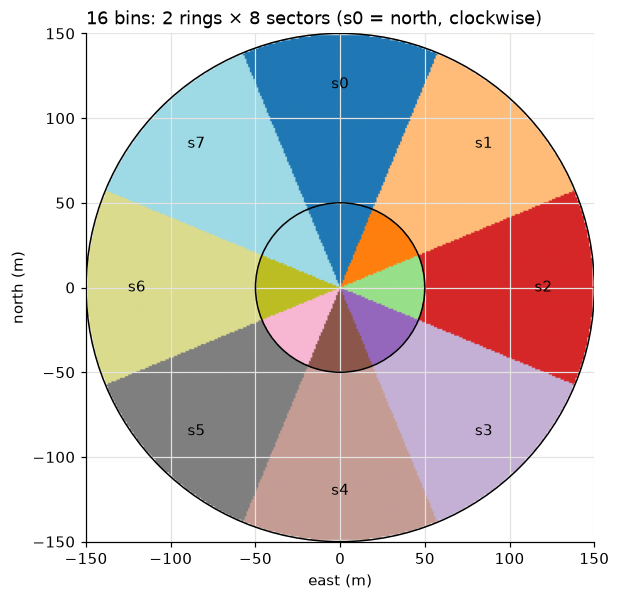

cells per bin: [[ 980  981  980  981  980  981  980  981]
 [7852 7857 7852 7857 7852 7857 7852 7857]]


In [10]:
from src.surrogate_dataset import disc_bins

sc = cfg["surrogate"]
dr, dc, b, n_bin = disc_bins(sc["radius_m"], sc["rings_m"], sc["n_sectors"], cfg["site"]["resolution_m"])
R = int(sc["radius_m"])
img = np.full((2 * R + 1, 2 * R + 1), np.nan)
img[R + dr, R + dc] = b
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img % sc["n_sectors"] + 0.35 * (img // sc["n_sectors"]), cmap="tab20",
          extent=(-R, R, -R, R))
for rad in sc["rings_m"][1:]:
    ax.add_patch(plt.Circle((0, 0), rad, fill=False, color="k", lw=1))
for k in range(sc["n_sectors"]):
    a = np.radians(k * 45)
    ax.annotate(f"s{k}", (120 * np.sin(a), 120 * np.cos(a)), ha="center", va="center", fontsize=10)
ax.set_title("16 bins: 2 rings × 8 sectors (s0 = north, clockwise)", loc="left")
ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)")
plt.show()
print("cells per bin:", n_bin.astype(int).reshape(2, -1))

Two observers of the site, a roof and the open ground near the centre, at every height:

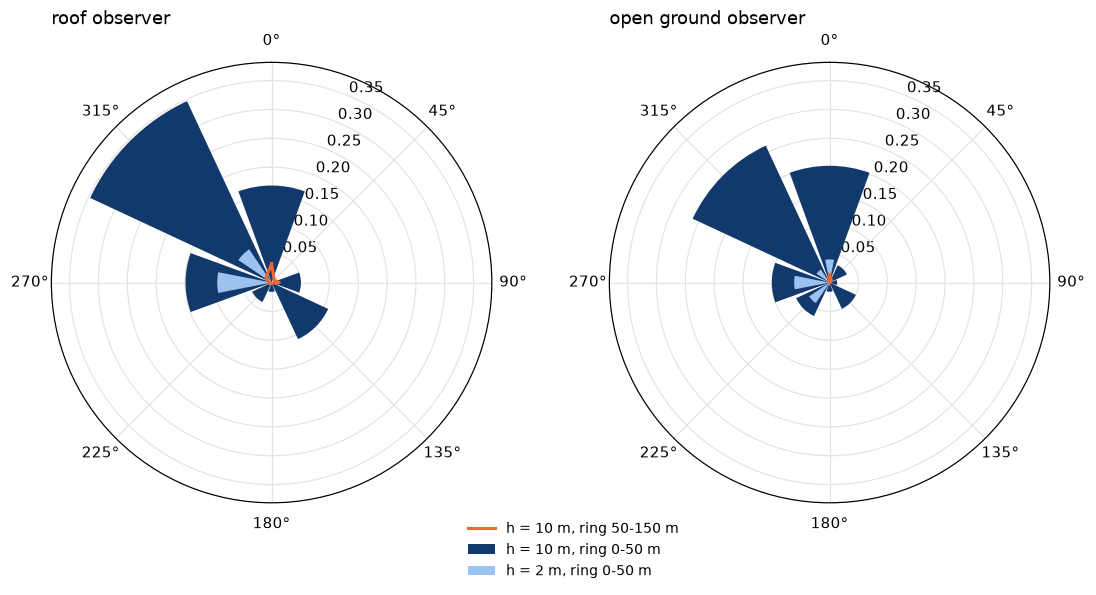

In [11]:
import geopandas as gpd

from src.surrogate_dataset import potential, strata
from src.viewshed import prepare_surfaces, to_pixel

s = prepare_surfaces(cfg)
g = s.grid
ground = s.z_opaque < s.z_tgt
st = strata(s, cfg)
per = gpd.read_file(cfg["site"]["gpkg"], layer="perimeter").geometry.iloc[0]
rc, cc_ = to_pixel(g, per.centroid.x, per.centroid.y)
rr, cc = np.indices(st.shape)
dist = np.hypot(rr - rc, cc - cc_)
obs = {}
for k, name in ((0, "roof"), (1, "open ground")):
    i = np.argmin(np.where(st == k, dist, np.inf))
    obs[name] = np.unravel_index(i, st.shape)
H = np.asarray(sc["heights_m"], float)
rows = np.array([o[0] for o in obs.values()], np.int64)
cols = np.array([o[1] for o in obs.values()], np.int64)
V = potential(s.z_opaque, s.z_veg, s.k_ext, s.z_tgt, ground, rows, cols, H, dr, dc, b, n_bin, g.res)
V = V.reshape(len(obs), H.size, 2, sc["n_sectors"])

theta = np.radians(np.arange(sc["n_sectors"]) * 45)
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), subplot_kw={"projection": "polar"})
for ax, (name, Vo) in zip(axes, zip(obs, V)):
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    for ih, col, wid in ((H.size - 1, "#12396b", 40), (0, "#9cc3ef", 22)):
        ax.bar(theta, Vo[ih, 0], width=np.radians(wid), color=col,
               label=f"h = {H[ih]:g} m, ring 0-50 m")
    ax.plot(np.r_[theta, theta[:1]], np.r_[Vo[-1, 1], Vo[-1, 1][:1]], color="#eb6834", lw=2,
            label=f"h = {H[-1]:g} m, ring 50-150 m")
    ax.set_ylim(0, 1.1 * V.max()); ax.set_title(f"{name} observer", loc="left")
axes[1].legend(loc="lower left", bbox_to_anchor=(-0.35, -0.2), frameon=False, fontsize=9)
plt.show()

Orientation matters (a camera pointed at the best sector sees several times more than the mean), height
matters (dark: 10 m, light: 2 m), and the far ring is almost never visible in this dense neighbourhood.

### The total potential of every position

The weighted mean over the bins, $\bar V_h = \sum_{a,s} |\mathcal{B}_{a,s}| V_{h,a,s} / \sum |\mathcal{B}|$,
summarises how much ground a position sees. This is the map a surrogate is supposed to predict in one pass;
here it is computed exactly every 3 m at $h$ = 6 m, on the positions of the site whose 150 m disc fits
inside the grid (the study buffer of the site is reduced, so the map does not reach its west edge):

675 positions in 0.9 s: 1.3 ms per position and height


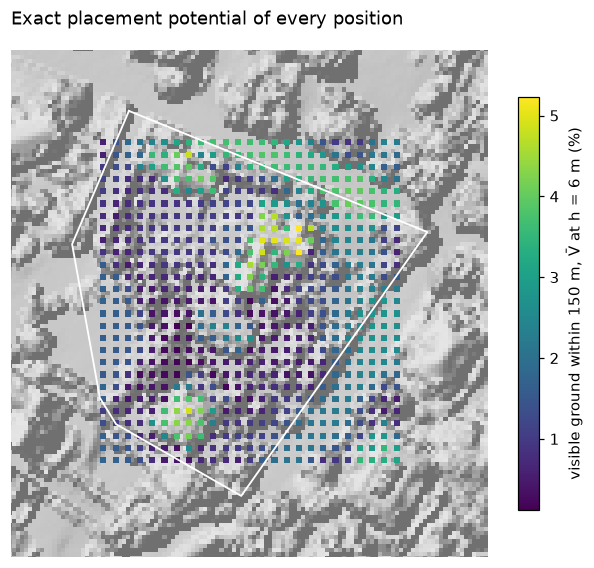

In [12]:
import time

from src.analysis import hillshade
from src.viewshed import read

x0, y0, x1, y1 = per.bounds
r_a, c_a = to_pixel(g, x0 - 10, y1 + 10)
r_b, c_b = to_pixel(g, x1 + 10, y0 - 10)
rg, cg = np.mgrid[r_a:r_b:3, c_a:c_b:3]
keep = (rg >= R) & (rg < g.height - R) & (cg >= R) & (cg < g.width - R)
rg, cg = rg[keep].astype(np.int64), cg[keep].astype(np.int64)
t0 = time.time()
Vm = potential(s.z_opaque, s.z_veg, s.k_ext, s.z_tgt, ground, rg, cg, np.array([6.0]), dr, dc, b, n_bin,
               g.res)[:, 0]
dt = time.time() - t0
vbar = Vm @ n_bin / n_bin.sum()
print(f"{rg.size} positions in {dt:.1f} s: {1e3 * dt / rg.size:.1f} ms per position and height")

dsm = read(Path(cfg["rasters"]["out_dir"]) / "dsm.tif")
hs = hillshade(np.nan_to_num(dsm, nan=np.nanmedian(dsm)))
ext = (g.xmin, g.xmax, g.ymin, g.ymax)
fig, ax = plt.subplots(figsize=(7, 6.5))
ax.imshow(hs, extent=ext, cmap="Greys_r", vmin=-0.8, vmax=1.4)
sca = ax.scatter(g.xmin + (cg + 0.5) * g.res, g.ymax - (rg + 0.5) * g.res, c=100 * vbar, s=16,
                 marker="s", cmap="viridis", lw=0)
ax.plot(*per.exterior.xy, color="w", lw=1.2)
ax.set_xlim(x0 - 15, x1 + 15); ax.set_ylim(y0 - 15, y1 + 15); ax.set_axis_off()
fig.colorbar(sca, ax=ax, shrink=0.75, label="visible ground within 150 m, V̄ at h = 6 m (%)")
ax.set_title("Exact placement potential of every position", loc="left")
plt.show()

## 2. Symmetries: an exact data augmentation

A 90° clockwise rotation of the terrain turns north into east: the sectors shift by $+2$. An east-west
mirror sends sector $s$ to $-s \bmod 8$. These 8 transformations (the dihedral group D4) act **exactly** on
the grid, so they give a data augmentation without any approximation. Check on a crop of the site:

In [13]:
half = R + 12
r0, c0 = obs["open ground"]
crop = (slice(r0 - half, r0 + half + 1), slice(c0 - half, c0 + half + 1))
Z = [a[crop] for a in (s.z_opaque, s.z_veg, s.k_ext, s.z_tgt)]
N = Z[0].shape[0]
centre = np.array([half], np.int64)


def V_at(zo, zv, k, zt, r, c):
    out = potential(zo, zv, k, zt, zo < zt, np.array([r], np.int64), np.array([c], np.int64),
                    np.array([6.0]), dr, dc, b, n_bin, g.res)
    return out.reshape(2, sc["n_sectors"])


base = V_at(*Z, half, half)
rot = [np.ascontiguousarray(np.rot90(a, k=-1)) for a in Z]            # clockwise
V_rot = V_at(*rot, half, N - 1 - half)                                 # (r, c) -> (c, N-1-r)
mir = [np.ascontiguousarray(a[:, ::-1]) for a in Z]
V_mir = V_at(*mir, half, N - 1 - half)
perm_rot = (np.arange(8) + 2) % 8
perm_mir = (8 - np.arange(8)) % 8
print("rotation: max |V_rot[perm] - V| =", float(np.abs(V_rot[:, perm_rot] - base).max()))
print("mirror  : max |V_mir[perm] - V| =", float(np.abs(V_mir[:, perm_mir] - base).max()))
pd.DataFrame({"sector": np.arange(8), "V (ring 0)": base[0].round(3),
              "V after rotation, sector s+2": V_rot[0, perm_rot].round(3)}).T

rotation: max |V_rot[perm] - V| = 0.0
mirror  : max |V_mir[perm] - V| = 0.0


,0,1,2,3,4,5,6,7
sector,0.000,1.000,2.000,3.000,4.000,5.000,6.000,7.000
V (ring 0),0.089,0.008,0.003,0.004,0.012,0.049,0.086,0.119
"V after rotation, sector s+2",0.089,0.008,0.003,0.004,0.012,0.049,0.086,0.119


## 3. The log-polar pyramid: horizons for a fraction of the cost

The raw U-Net underfits: rebuilding a maximum along rays divided by the distance with 3 × 3 convolutions is
a missing inductive bias. The physical baseline B1 instead uses, per sector $s$ and distance band $b$, the
**horizon angle**

$$
A_{h,b,s}(o) = \arctan \max_{j \in \text{wedge}(b, s)} \frac{z(j) - z(o) - h}{d_{oj}},
$$

which costs 70,680 cell reads per position. The pyramid reads, in band $b$, a square **block** of
$p_b \times p_b$ cells every $p_b$ pixels ($p_b$ = 1, 3, 5, 9, 15 for the bands 0-10, 10-25, 25-50, 50-100,
100-150 m), each block carrying the max of its cells, computed once for the whole grid by a sliding filter.
The number of blocks per band stays roughly constant: the resolution degrades with the distance, like the
angular size of an obstacle.

1,204 blocks read per position instead of 70,680 cells


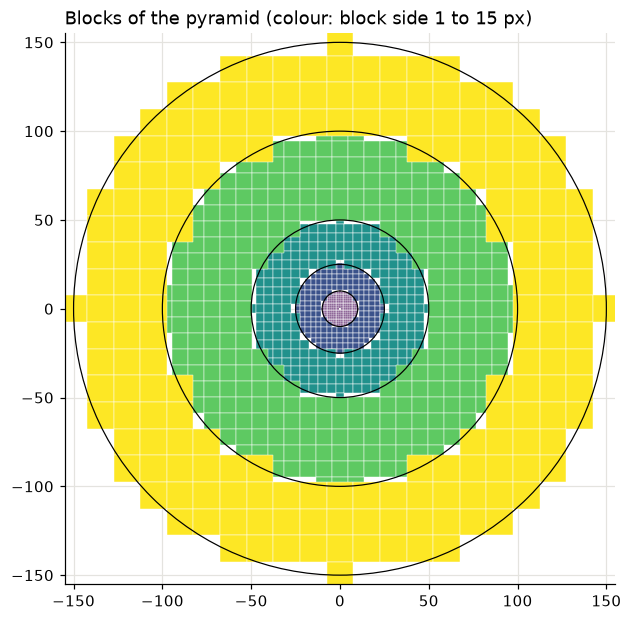

In [14]:
from src.horizons import block_lattice

hc = sc["horizons"]
bdr, bdc, lvl, band, sect, bdist = block_lattice(hc["bands_m"], hc["step_px"], sc["n_sectors"], g.res)
print(f"{bdr.size:,} blocks read per position instead of {dr.size:,} cells")
fig, ax = plt.subplots(figsize=(6.5, 6.5))
cmap = plt.get_cmap("viridis", len(hc["step_px"]))
for x_, y_, L in zip(bdc, -bdr, lvl):
    p = hc["step_px"][L]
    ax.add_patch(plt.Rectangle((x_ - p / 2, y_ - p / 2), p, p, fc=cmap(L), ec="white", lw=0.3))
for rad in hc["bands_m"][1:]:
    ax.add_patch(plt.Circle((0, 0), rad, fill=False, color="k", lw=0.8))
ax.set_xlim(-155, 155); ax.set_ylim(-155, 155); ax.set_aspect("equal")
ax.set_title("Blocks of the pyramid (colour: block side 1 to 15 px)", loc="left")
plt.show()

In [15]:
from src.horizons import Horizons
from src.surrogate_baselines import _descriptors, band_offsets

hz = Horizons(s, cfg)
rb, cb = np.mgrid[r0 - 30:r0 + 30, c0 - 30:c0 + 30]            # a contiguous 60 × 60 block
rb, cb = rb.ravel().astype(np.int64), cb.ravel().astype(np.int64)
hz(rb[:5], cb[:5])                                                 # numba compilation
t0 = time.time(); P_hor, _ = hz(rb, cb); t_pyr = (time.time() - t0) / rb.size

odr, odc, osect, oband, od = band_offsets(cfg)
h64 = hz.h.astype(np.float64)
_descriptors(s.z_opaque, s.z_veg, s.k_ext, ground, rb[:5], cb[:5], h64, odr, odc, osect, oband, od, 8, 5)
t0 = time.time()
E = _descriptors(s.z_opaque, s.z_veg, s.k_ext, ground, rb, cb, h64, odr, odc, osect, oband, od, 8, 5)
t_exact = (time.time() - t0) / rb.size
E = E.reshape(rb.size, h64.size, 8, 5, 4)
exact = np.arctan(E[..., 0]).transpose(0, 1, 3, 2)                  # (n, h, band, sector)

rows = []
for ib in range(5):
    e = np.degrees(P_hor[:, 2, 0, ib] - exact[:, 2, ib])            # h = 6 m, opaque horizon
    rows.append({"band": f"{hc['bands_m'][ib]:g}-{hc['bands_m'][ib + 1]:g} m",
                 "block side (px)": hc["step_px"][ib], "bias (°)": round(e.mean(), 2),
                 "mean |error| (°)": round(np.abs(e).mean(), 2),
                 "p95 |error| (°)": round(np.quantile(np.abs(e), 0.95), 2)})
print(f"cost per position (5 heights): pyramid {1e3 * t_pyr:.3f} ms, exact {1e3 * t_exact:.2f} ms "
      f"-> x{t_exact / t_pyr:.0f}")
pd.DataFrame(rows)

cost per position (5 heights): pyramid 0.004 ms, exact 0.07 ms -> x20


,band,block side (px),bias (°),mean |error| (°),p95 |error| (°)
0,0-10 m,1,0.00,0.00,0.00
1,10-25 m,3,0.09,1.12,4.73
2,25-50 m,5,0.30,1.27,6.40
3,50-100 m,9,0.08,0.46,1.86
4,100-150 m,15,0.06,0.48,2.17


The error has no fixed sign (the highest cell of a block can be closer or farther than its centre) and the
nearest band is exact. The speed-up depends on the machine and on the number of positions (numba runs in
parallel). Used as input features, these horizons give a boosting model (**B2**) that matches the
exact horizons (B1) once the **ground share per bin**, which bounds $V$, is added: the approximation costs
nothing measurable.

## 4. From a potential map to a choice of positions

The models are compared on the test block (spatially separated from training by a 30 m buffer), at $h$ = 6 m,
by `python -m src.surrogate_metrics` (MAE on V, Spearman on V̄, cost per position). An accurate model can then
be asked to **choose candidate positions** (`src.surrogate_catalog`, `src.reduced_catalog`), against a random
draw with the same spacing, under a preregistered protocol. A limit is expected whatever the model: coverage is **submodular**,
the value of a position depends on those already chosen, and a per-position score cannot capture the
redundancy between positions that all look at the same zones. Choosing a set is not ranking elements, which
is exactly what the greedy and the certified optimum of [notebook 04](04_coverage_optimisation.ipynb)
handle, from the exact coverage matrix.